In [1]:
!pip -q install wandb scikit-learn
import wandb
wandb.login()

/usr/local/lib/python3.13/dist-packages/notebook/notebookapp.py:191: SyntaxWarning: invalid escape sequence '\/'
  | |_| | '_ \/ _` / _` |  _/ -_)
wandb: (1) Create a W&B account
wandb: (2) Use an existing W&B account
wandb: (3) Don't visualize my results


wandb: Enter your choice: 2


wandb: You chose 'Use an existing W&B account'
wandb: Logging into https://api.wandb.ai. (Learn how to deploy a W&B server locally: https://wandb.me/wandb-server)
wandb: Create a new API key at: https://wandb.ai/authorize?ref=models
wandb: Store your API key securely and do not share it.


wandb: Paste your API key and hit enter: ··········


wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: tehami-azmat (tehami-azmat-fast-nuces) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


True

In [2]:
from google.colab import files
files.upload()
!unzip -q -o final_dataset.zip -d .
!ls final_dataset

Saving final_dataset.zip to final_dataset.zip
manifest.csv	  preview_train.jpg  test   val
preview_test.jpg  preview_val.jpg    train


**Train with cross-entropy and the balanced sampler**

In [4]:
!python train.py --data final_dataset --out outputs --epochs 30 --loss ce --imbalance sampler --run_name ce_sampler

Using pre-split dataset (source-level split, no leakage).
Classes: ['paper', 'rock', 'scissors'] | per-class: {'paper': 851, 'rock': 700, 'scissors': 549} | total: 2100 | train/val/test: 1470 315 315
/content/train.py:144: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=device == "cuda")
wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from /root/.netrc.
wandb: Currently logged in as: tehami-azmat (tehami-azmat-fast-nuces) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin
wandb: Using an existing wandb-core service via WANDB_SERVICE.
wandb: ⢿ Waiting for wandb.init()...
wandb: ⣻ Waiting for wandb.init()...
wandb: ⣽ Waiting for wandb.init()...
wandb: ⣾ Waiting for wandb.init()...
wandb: ⣷ setting up run 0obspa73 (0.2s)
wandb: ⣯ setting up run 0obspa73 (0.2s)
wandb: ⣟ setting up run 0obspa73 (0.2s)
wandb: Tracking run with wandb

**Train with focal loss for the comparison**

In [5]:
!python train.py --data final_dataset --out outputs_focal --epochs 30 --loss focal --gamma 2.0 --imbalance sampler --run_name focal_sampler

Using pre-split dataset (source-level split, no leakage).
Classes: ['paper', 'rock', 'scissors'] | per-class: {'paper': 851, 'rock': 700, 'scissors': 549} | total: 2100 | train/val/test: 1470 315 315
/content/train.py:144: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=device == "cuda")
wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from /root/.netrc.
wandb: Currently logged in as: tehami-azmat (tehami-azmat-fast-nuces) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin
wandb: Using an existing wandb-core service via WANDB_SERVICE.
wandb: ⢿ Waiting for wandb.init()...
wandb: ⣻ Waiting for wandb.init()...
wandb: ⣽ Waiting for wandb.init()...
wandb: ⣾ Waiting for wandb.init()...
wandb: ⣷ setting up run m3hakkbd (0.3s)
wandb: ⣯ setting up run m3hakkbd (0.3s)
wandb: Tracking run with wandb version 0.28.1
wandb: Run data is saved

**Results**

outputs | test acc 0.7524 | macro-F1 0.7528
    normal acc 0.752
    dark x0.3 acc 0.743
    dark x0.5 acc 0.749
    bright x1.6 acc 0.711
    bright x2.5 acc 0.562
    low contrast acc 0.749
    high contrast acc 0.743
    gamma 0.5 acc 0.810
    gamma 2.0 acc 0.676


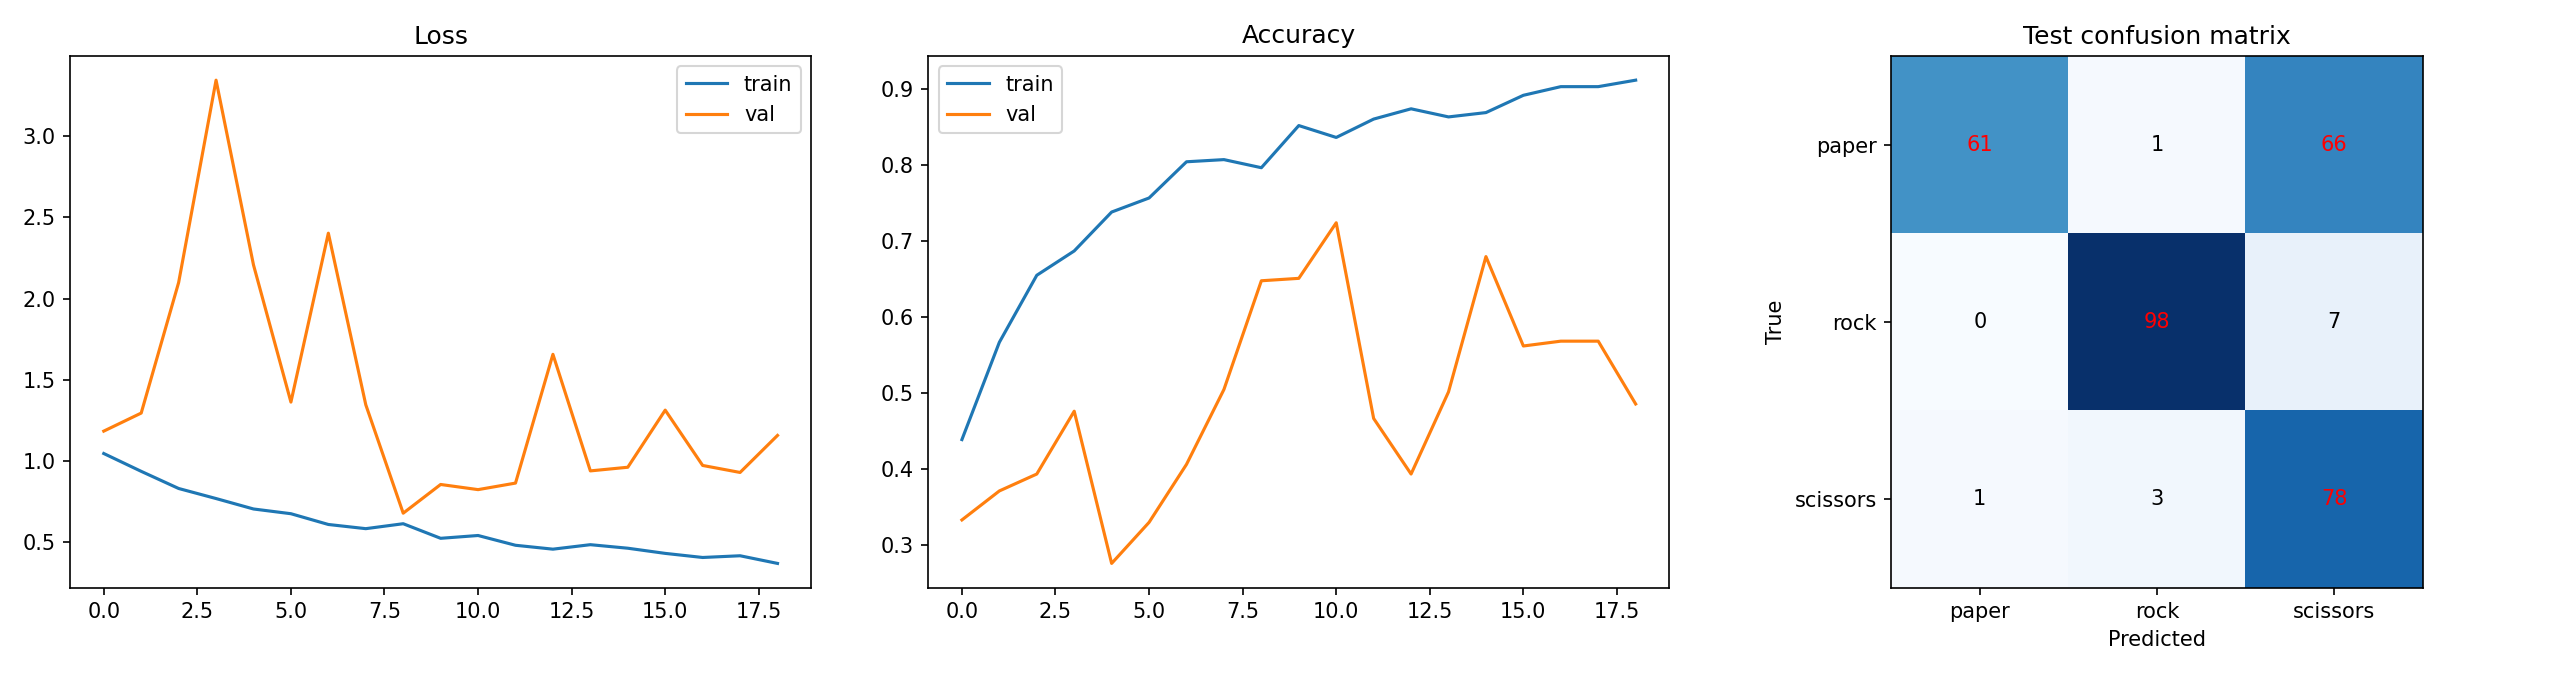

outputs_focal | test acc 0.5683 | macro-F1 0.4995
    normal acc 0.568
    dark x0.3 acc 0.568
    dark x0.5 acc 0.568
    bright x1.6 acc 0.521
    bright x2.5 acc 0.521
    low contrast acc 0.568
    high contrast acc 0.533
    gamma 0.5 acc 0.556
    gamma 2.0 acc 0.571


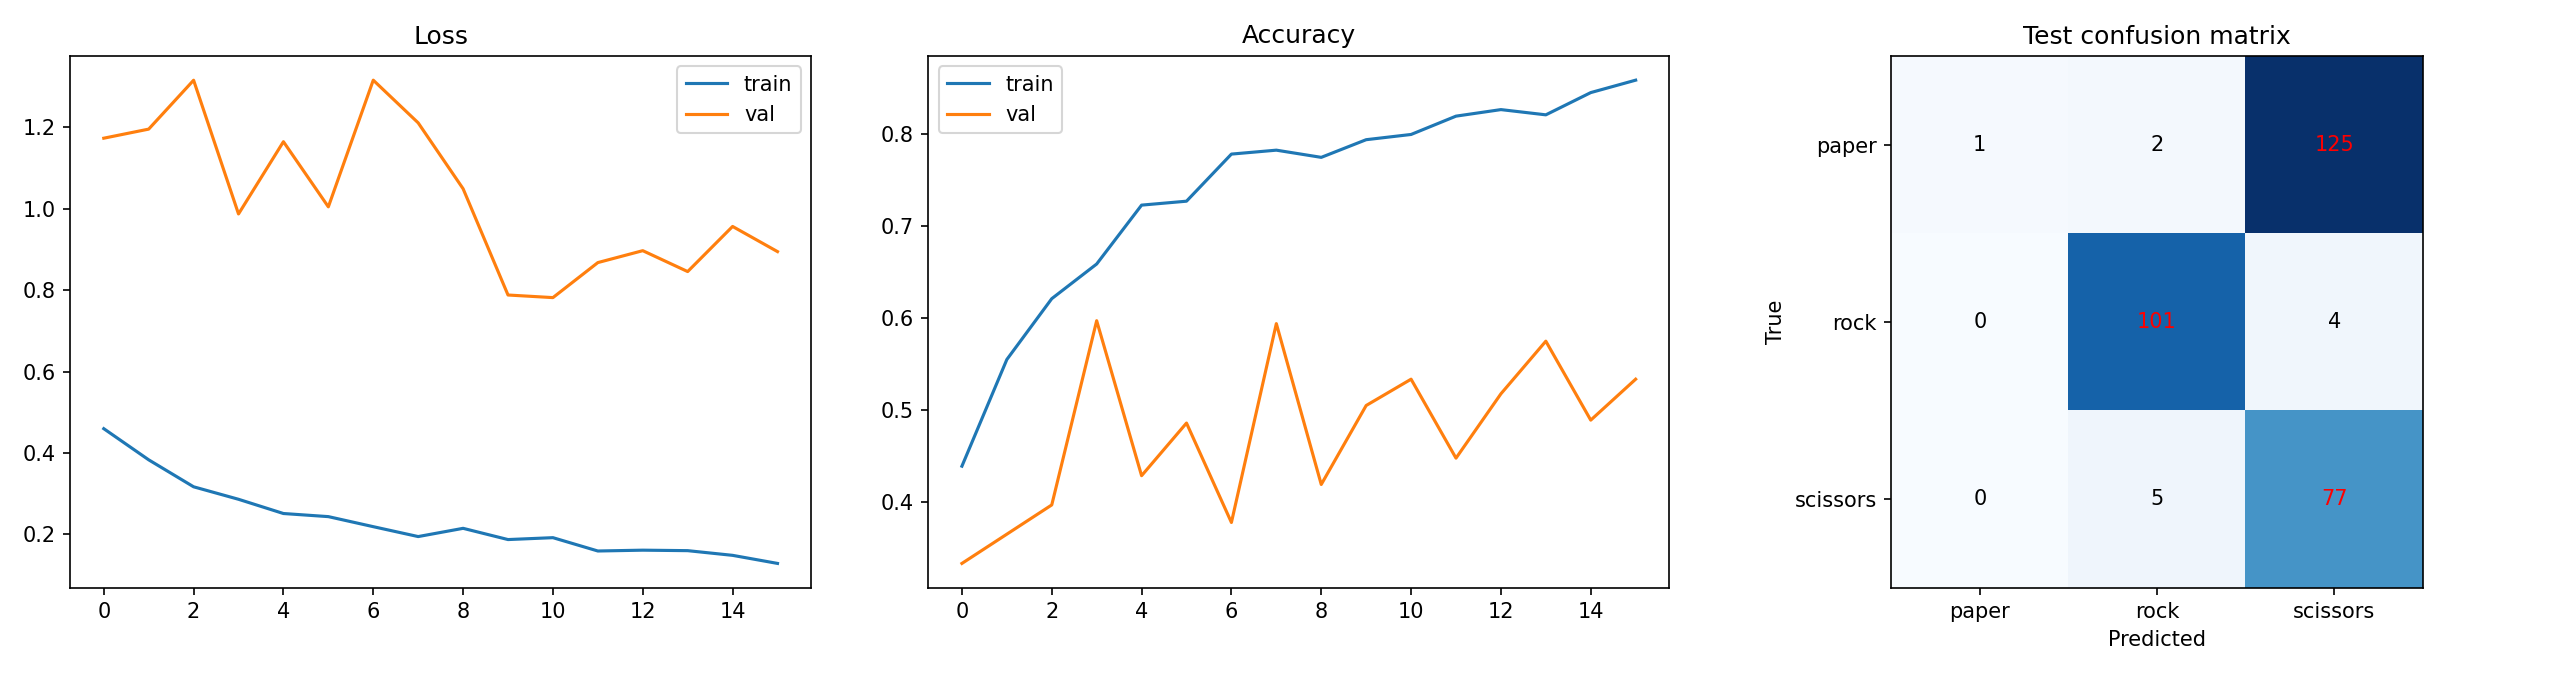

In [6]:
import json
from IPython.display import Image, display
for d in ['outputs', 'outputs_focal']:
    r = json.load(open(f'{d}/results.json'))
    print(d, '| test acc %.4f | macro-F1 %.4f' % (r['test_acc'], r['test_macro_f1']))
    for k, v in r['lighting_robustness'].items():
        print('   ', k, 'acc %.3f' % v['acc'])
    display(Image(f'{d}/training_summary.png'))

In [ ]:
from google.colab import files
files.download('outputs/rps_best.pt')
files.download('outputs/results.json')
files.download('outputs/training_summary.png')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**Shell Code**

In [7]:
!python train.py --data final_dataset --out outputs --epochs 40 --patience 100 --lr 1e-3 --loss ce --imbalance sampler --run_name ce_full

Using pre-split dataset (source-level split, no leakage).
Classes: ['paper', 'rock', 'scissors'] | per-class: {'paper': 851, 'rock': 700, 'scissors': 549} | total: 2100 | train/val/test: 1470 315 315
/content/train.py:144: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=device == "cuda")
wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from /root/.netrc.
wandb: Currently logged in as: tehami-azmat (tehami-azmat-fast-nuces) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin
wandb: Using an existing wandb-core service via WANDB_SERVICE.
wandb: ⢿ Waiting for wandb.init()...
wandb: ⣻ Waiting for wandb.init()...
wandb: ⣽ Waiting for wandb.init()...
wandb: ⣾ Waiting for wandb.init()...
wandb: ⣷ setting up run 7yim8a2b (0.2s)
wandb: ⣯ setting up run 7yim8a2b (0.2s)
wandb: ⣟ setting up run 7yim8a2b (0.2s)
wandb: ⡿ setting up run 7yim8a

['paper', 'rock', 'scissors']
[[118   0  10]
 [  0  60  45]
 [ 70   0  12]]
img_Paper12               n=  1 acc=1.00
img_Paper4                n=  1 acc=0.00
img_Rock10                n=  1 acc=1.00
img_Rock6                 n=  1 acc=1.00
img_Scissor14             n=  1 acc=0.00
img_Scissor9              n=  1 acc=0.00
vid_Paper4                n= 63 acc=0.98
vid_Paper5                n= 63 acc=0.87
vid_Rock                  n=103 acc=0.56
vid_Scissor4              n= 80 acc=0.15


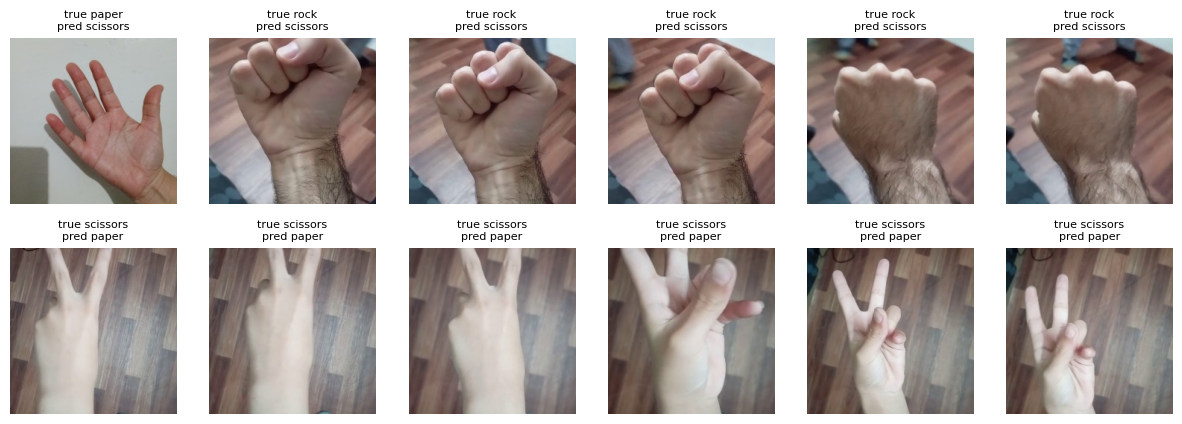

In [10]:
import os, collections, numpy as np, torch
import matplotlib.pyplot as plt
from PIL import Image
from torchvision import datasets
from sklearn.metrics import confusion_matrix
from model import load_checkpoint, eval_transform

d = 'outputs'   # or 'outputs_full'
dev = 'cuda' if torch.cuda.is_available() else 'cpu'
model, classes, img = load_checkpoint(f'{d}/rps_best.pt', dev)
ds = datasets.ImageFolder('final_dataset/test', transform=eval_transform(img))

preds = []
with torch.no_grad():
    for i in range(0, len(ds), 64):
        x = torch.stack([ds[j][0] for j in range(i, min(i + 64, len(ds)))]).to(dev)
        preds += model(x).argmax(1).cpu().tolist()
y = np.array([t for _, t in ds.samples]); p = np.array(preds)

print(classes); print(confusion_matrix(y, p))
src = [os.path.basename(pth).rsplit('_f', 1)[0] for pth, _ in ds.samples]
acc = collections.defaultdict(list)
for s, a, b in zip(src, y, p): acc[s].append(a == b)
for s, v in sorted(acc.items()): print(f'{s:25s} n={len(v):3d} acc={np.mean(v):.2f}')

wrong = np.where(y != p)[0]
wrong = wrong[::max(1, len(wrong) // 12)][:12]
fig, ax = plt.subplots(2, 6, figsize=(15, 5))
for a_, k in zip(ax.ravel(), wrong):
    a_.imshow(Image.open(ds.samples[k][0])); a_.axis('off')
    a_.set_title(f'true {classes[y[k]]}\npred {classes[p[k]]}', fontsize=8)
plt.show()

**Looking for frames pattern**

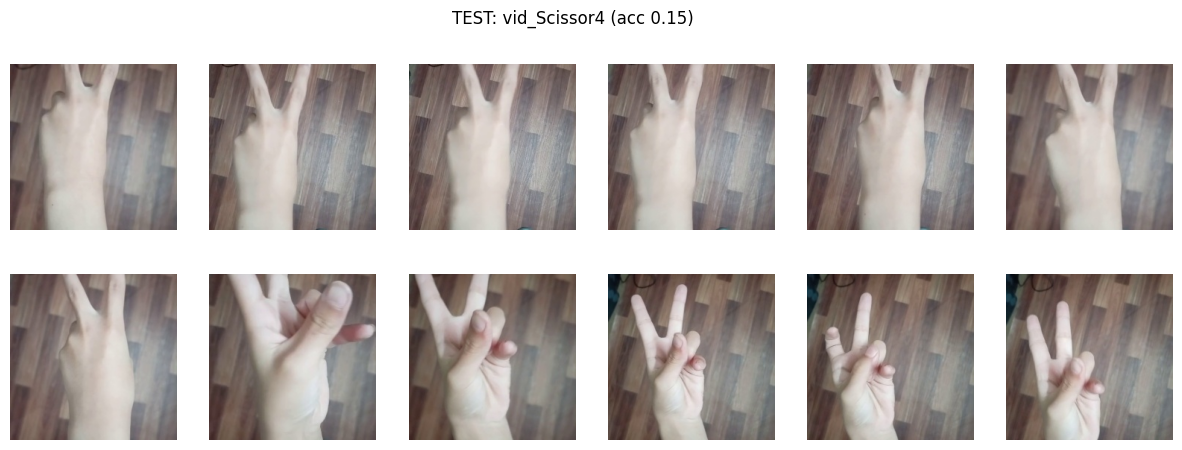

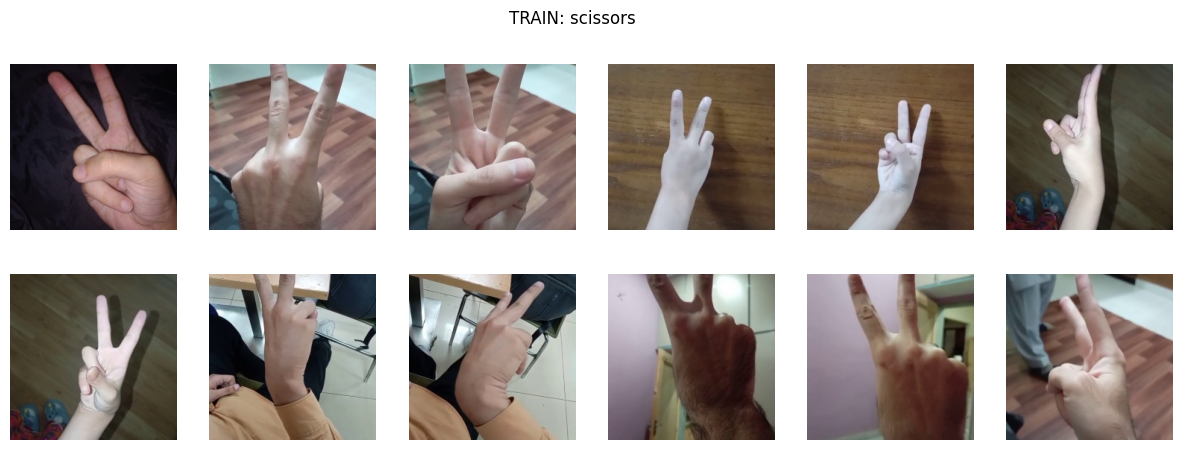

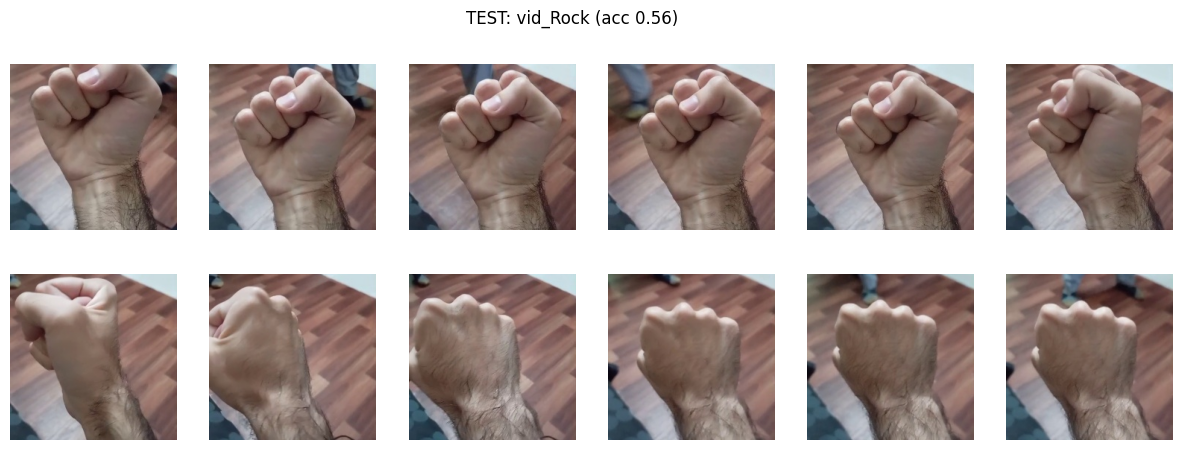

In [11]:
import glob
import matplotlib.pyplot as plt
from PIL import Image

def show(paths, title, n=12):
    paths = paths[::max(1, len(paths) // n)][:n]
    fig, ax = plt.subplots(2, 6, figsize=(15, 5)); fig.suptitle(title)
    for a_, pth in zip(ax.ravel(), paths):
        a_.imshow(Image.open(pth)); a_.axis('off')
    plt.show()

show(sorted(glob.glob('final_dataset/test/scissors/vid_Scissor4_f*.jpg')), 'TEST: vid_Scissor4 (acc 0.15)')
show(sorted(glob.glob('final_dataset/train/scissors/*.jpg')), 'TRAIN: scissors')
show(sorted(glob.glob('final_dataset/test/rock/vid_Rock_f*.jpg')), 'TEST: vid_Rock (acc 0.56)')

**Kfold Code**

In [13]:
!python kfold.py --data final_dataset --k 5 --epochs 30 --run_name kfold

2100 images from 67 source clips | per class: {'paper': 851, 'rock': 700, 'scissors': 549}

=== fold 1/5: train 1516 imgs | test 584 imgs from clips ['img_Paper1', 'img_Paper12', 'img_Paper3', 'img_Paper4', 'img_Paper8', 'img_Rock12', 'img_Rock14', 'img_Rock4', 'img_Scissor11', 'img_Scissor14', 'img_Scissor8', 'vid_Paper', 'vid_Paper4', 'vid_Paper8', 'vid_Rock3', 'vid_Rock4', 'vid_Scissor', 'vid_Scissor7']
wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from /root/.netrc.
wandb: Currently logged in as: tehami-azmat (tehami-azmat-fast-nuces) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin
wandb: Using an existing wandb-core service via WANDB_SERVICE.
wandb: ⢿ Waiting for wandb.init()...
wandb: ⣻ Waiting for wandb.init()...
wandb: ⣽ Waiting for wandb.init()...
wandb: ⣾ Waiting for wandb.init()...
wandb: ⣷ Waiting for wandb.init()...
wandb: ⣯ Waiting for wandb.init()...
wandb: ⣟ Waiting for wandb.init()...
wandb: ⡿ Waiting for wandb.init()...
wandb

**Worst Clips**


In [14]:
import json
r = json.load(open('outputs_kfold/kfold_results.json'))
for s, a in sorted(r['per_clip_acc'].items(), key=lambda kv: kv[1]):
    if s.startswith('vid_'): print(f'{s:15s} {a:.2f}')

vid_Rock4       0.00
vid_Scissor6    0.00
vid_Rock2       0.05
vid_Rock8       0.10
vid_Rock9       0.17
vid_Scissor4    0.19
vid_Paper10     0.21
vid_Scissor7    0.26
vid_Paper2      0.30
vid_Scissor8    0.30
vid_Paper3      0.44
vid_Paper5      0.68
vid_Scissor5    0.85
vid_Rock3       0.89
vid_Paper       0.92
vid_Paper8      0.92
vid_Paper6      0.95
vid_Paper4      0.95
vid_Rock        0.96
vid_Paper7      0.98
vid_Scissor     0.98
vid_Scissor3    0.98
vid_Paper9      1.00
vid_Rock5       1.00
vid_Scissor2    1.00


In [15]:
!python kfold.py --data final_dataset --skip_cv --final --epochs 30 --run_name kfold
from google.colab import files
files.download('outputs_kfold/rps_final.pt')
files.download('outputs_kfold/kfold_results.json')
files.download('outputs_kfold/kfold_summary.png')

2100 images from 67 source clips | per class: {'paper': 851, 'rock': 700, 'scissors': 549}

=== final model on ALL clips (same recipe, final-epoch weights) ===
wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from /root/.netrc.
wandb: Currently logged in as: tehami-azmat (tehami-azmat-fast-nuces) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin
wandb: Using an existing wandb-core service via WANDB_SERVICE.
wandb: ⢿ Waiting for wandb.init()...
wandb: ⣻ Waiting for wandb.init()...
wandb: ⣽ Waiting for wandb.init()...
wandb: ⣾ Waiting for wandb.init()...
wandb: ⣷ setting up run 6inxltrg (0.3s)
wandb: ⣯ setting up run 6inxltrg (0.3s)
wandb: ⣟ setting up run 6inxltrg (0.3s)
wandb: Tracking run with wandb version 0.28.1
wandb: Run data is saved locally in /content/wandb/run-20261030_121538-6inxltrg
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run kfold_final
wandb: ⭐️ View project at https://wandb.ai/tehami-azmat-fast-nuces/rps-applied

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>